# Scan i15-1-100585: I0 versus synchrotron ring current

Read the NeXus file **read-only**, pair monitors by stored scan-point index, and associate them with the EIGER detector-arm angle $2\theta$. These are **detector positions**, not the full diffraction-angle coverage of each image.

The plots distinguish an I0-only change from a ring-current jump. A pre-change affine reference tests linear tracking with a possible constant offset; a proportional reference tests constant I0/current. Neither proves which monitor is at fault. No detector images are loaded and no corrections are applied.

In [1]:
from pathlib import Path
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

NEXUS_PATH = Path('/dls/i15-1/data/2026/cm44163-4/i15-1-100585.nxs')
if not NEXUS_PATH.is_file():
    raise FileNotFoundError(NEXUS_PATH)

# Inspect metadata only: no detector image data are read or modified.
candidates = []
with h5py.File(NEXUS_PATH, 'r') as nexus:
    def inspect_monitor(name, obj):
        if isinstance(obj, h5py.Dataset) and any(term in name.lower() for term in ('i0', 'ring', 'current', 'tth', 'exposure', 'count_time', 'timestamp')):
            row = {'path': name, 'shape': obj.shape, 'dtype': str(obj.dtype), 'units': str(obj.attrs.get('units', ''))}
            if obj.size <= 12:
                row['value'] = str(obj[()])
            candidates.append(row)
    nexus.visititems(inspect_monitor)
    for key in ('entry/start_time', 'entry/end_time', 'entry/scan_command'):
        if key in nexus:
            print(key, nexus[key][()])
display(pd.DataFrame(candidates))

entry/start_time b'2026-10-15T21:35:23.749'
entry/end_time b'2026-10-15T21:42:28.820'


,path,shape,dtype,units,value
0,entry/fastcs_eiger/tth,"(31,)",float64,b'deg',NaN
1,entry/instrument/i0/driver-averaging_time,(),float64,b'',10.0
2,entry/instrument/i0/driver-sample_time,(),float64,b'',0.001
3,entry/instrument/i0/driver-values_per_reading,(),int32,b'',100
4,entry/instrument/i0/local_name,(),object,,b'i0'
5,entry/instrument/synchrotron/current,"(31,)",float64,b'mA',NaN
6,entry/instrument/tth/encoder_resolution,(),float64,b'deg',5.54923e-05
7,entry/instrument/tth/local_name,(),object,,b'tth'
8,entry/instrument/tth/motor_egu,(),object,,b'deg'
9,entry/instrument/tth/motor_resolution,(),float64,b'deg',5.54923e-05


In [3]:
I0_PATH = 'entry/instrument/i0/data'
CURRENT_PATH = 'entry/instrument/synchrotron/current'
ANGLE_PATH = 'entry/fastcs_eiger/tth'

def text(value):
    return value.decode() if isinstance(value, bytes) else str(value)

with h5py.File(NEXUS_PATH, 'r') as nexus:
    angle = np.asarray(nexus[ANGLE_PATH][()], dtype=float).reshape(-1)
    i0 = np.asarray(nexus[I0_PATH][()], dtype=float).reshape(-1)
    current = np.asarray(nexus[CURRENT_PATH][()], dtype=float).reshape(-1)
    i0_units = text(nexus[I0_PATH].attrs.get('units', 'unspecified units'))
    current_units = text(nexus[CURRENT_PATH].attrs.get('units', 'mA'))
    exposure_seconds = float(nexus['entry/plan_metadata/exposure_time_per_frame'][()])
    start_time = text(nexus['entry/start_time'][()])
    end_time = text(nexus['entry/end_time'][()])
assert len(angle) == len(i0) == len(current), 'Monitor/angle lengths do not match.'
points = pd.DataFrame({'point': np.arange(len(angle)), 'two_theta_deg': angle, 'ring_current_mA': current, 'i0': i0})
points['valid'] = np.isfinite(angle) & np.isfinite(i0) & np.isfinite(current) & (current > 0) & (i0 > 0)
points['i0_per_mA'] = points.i0 / points.ring_current_mA
print(f'{len(points)} scan points; {points.valid.sum()} valid. Exposure: {exposure_seconds:g} s/frame.')
print(f'I0: {I0_PATH} [{i0_units}]; ring current: {CURRENT_PATH} [{current_units}]')
print(f'Angle: {ANGLE_PATH}; acquisition {start_time} to {end_time}')
display(points.round(6))

31 scan points; 31 valid. Exposure: 10 s/frame.
I0: entry/instrument/i0/data [unspecified units]; ring current: entry/instrument/synchrotron/current [mA]
Angle: entry/fastcs_eiger/tth; acquisition 2026-10-15T21:35:23.749 to 2026-10-15T21:42:28.820


,point,two_theta_deg,ring_current_mA,i0,valid,i0_per_mA
0,0,0.000000,299.527447,0.052481,True,0.000175
1,1,5.548398,299.444023,0.052481,True,0.000175
2,2,9.013392,299.342883,0.052477,True,0.000175
3,3,11.971576,299.258581,0.052465,True,0.000175
4,4,14.642309,299.175537,0.052467,True,0.000175
5,5,17.117710,299.072269,0.052437,True,0.000175
6,6,19.447887,298.989263,0.052407,True,0.000175
7,7,21.663805,298.905381,0.052380,True,0.000175
8,8,23.786386,298.803705,0.052365,True,0.000175
9,9,25.830722,298.718937,0.052326,True,0.000175


## Reference models and screening rule

The raw sequence first rises against the falling current at **38.64°**. Use the preceding points (0–36.94°) as an **exploratory, manually selected reference**, adjustable below—not an independently certified good region.

1. Fit $I_0=a(C-C_\mathrm{ref})+b$ on this region only, to avoid absorbing the later change into the fit.
2. Also show $I_0=kC$, with $k$ the median reference I0/current ratio. This tests proportional tracking but does not allow an electronic dark offset.
3. Flag affine-model residuals above the larger of **5 robust reference scatter estimates** or **0.10%**. This is a screening threshold, not a significance test or an automatic exclusion rule. The current range outside the reference is extrapolation; late flags are therefore model-dependent.

Monitor timestamps/averaging windows are not established by equal array lengths. The I0 metadata are shown above; the nominal 10 s exposure must not be interpreted as a measured monitor timestamp.

In [4]:
REFERENCE_MAX_ANGLE_DEG = 37.0
MIN_DEVIATION_PERCENT = 0.10
ROBUST_SCATTER_MULTIPLIER = 5.0

reference = points.valid & (points.two_theta_deg <= REFERENCE_MAX_ANGLE_DEG)
assert reference.sum() >= 4, 'Choose at least four reference points.'
c_ref = points.loc[reference, 'ring_current_mA'].mean()
x_ref = points.loc[reference, 'ring_current_mA'].to_numpy() - c_ref
y_ref = points.loc[reference, 'i0'].to_numpy()
assert np.ptp(x_ref) > 0, 'Reference current has no variation.'
slope, intercept_at_ref = np.polyfit(x_ref, y_ref, 1)
ratio_reference = points.loc[reference, 'i0_per_mA'].median()
points['reference'] = reference
points['affine_expected_i0'] = slope * (points.ring_current_mA - c_ref) + intercept_at_ref
points['affine_residual_percent'] = 100 * (points.i0 / points.affine_expected_i0 - 1)
points['ratio_deviation_percent'] = 100 * (points.i0_per_mA / ratio_reference - 1)
ref_residual = points.loc[reference, 'affine_residual_percent'].to_numpy()
robust_scatter = 1.4826 * np.median(np.abs(ref_residual - np.median(ref_residual)))
threshold_percent = max(MIN_DEVIATION_PERCENT, ROBUST_SCATTER_MULTIPLIER * robust_scatter)
c_min = points.loc[reference, 'ring_current_mA'].min()
c_max = points.loc[reference, 'ring_current_mA'].max()
points['extrapolated'] = ~points.ring_current_mA.between(c_min, c_max)
points['flag_affine'] = points.valid & (points.affine_residual_percent.abs() > threshold_percent)
points['flag_proportional'] = points.valid & (points.ratio_deviation_percent.abs() > threshold_percent)
points['current_step_mA'] = points.ring_current_mA.diff()
# A large positive discontinuity, not a confirmed injection timestamp.
points['current_jump'] = points.current_step_mA > 0.5
reference_r2 = 1 - np.sum((y_ref - points.loc[reference, 'affine_expected_i0'])**2) / np.sum((y_ref - y_ref.mean())**2)
print(f'Reference: {reference.sum()} points, 0–{points.loc[reference, "two_theta_deg"].max():.4f}°; current {c_min:.4f}–{c_max:.4f} mA')
print(f'I0 = {slope:.7g} × (current − {c_ref:.6f}) + {intercept_at_ref:.7g}; reference R² = {reference_r2:.4f}')
print(f'Reference robust residual scatter: {robust_scatter:.4f}%; screening threshold: ±{threshold_percent:.4f}%')
print('All-point Pearson correlation:', points.loc[points.valid, ['i0', 'ring_current_mA']].corr().iloc[0, 1])
result_columns = ['point', 'two_theta_deg', 'ring_current_mA', 'i0', 'affine_residual_percent', 'ratio_deviation_percent', 'extrapolated', 'flag_affine', 'flag_proportional', 'current_jump']
display(points[result_columns].round(6))

Reference: 16 points, 0–36.9343°; current 298.1827–299.5274 mA
I0 = 0.0002452226 × (current − 298.853304) + 0.0523596; reference R² = 0.9618
Reference robust residual scatter: 0.0390%; screening threshold: ±0.1948%
All-point Pearson correlation: 0.7983626803718062


,point,two_theta_deg,ring_current_mA,i0,affine_residual_percent,ratio_deviation_percent,extrapolated,flag_affine,flag_proportional,current_jump
0,0,0.000000,299.527447,0.052481,-0.084381,-0.009403,False,False,False,False
1,1,5.548398,299.444023,0.052481,-0.044393,0.019513,False,False,False,False
2,2,9.013392,299.342883,0.052477,-0.004586,0.045872,False,False,False,False
3,3,11.971576,299.258581,0.052465,0.012346,0.051572,False,False,False,False
4,4,14.642309,299.175537,0.052467,0.053549,0.081708,False,False,False,False
5,5,17.117710,299.072269,0.052437,0.044835,0.059203,False,False,False,False
6,6,19.447887,298.989263,0.052407,0.026627,0.029904,False,False,False,False
7,7,21.663805,298.905381,0.052380,0.015294,0.007359,False,False,False,False
8,8,23.786386,298.803705,0.052365,0.033387,0.011852,False,False,False,False
9,9,25.830722,298.718937,0.052326,-0.002174,-0.035043,False,False,False,False


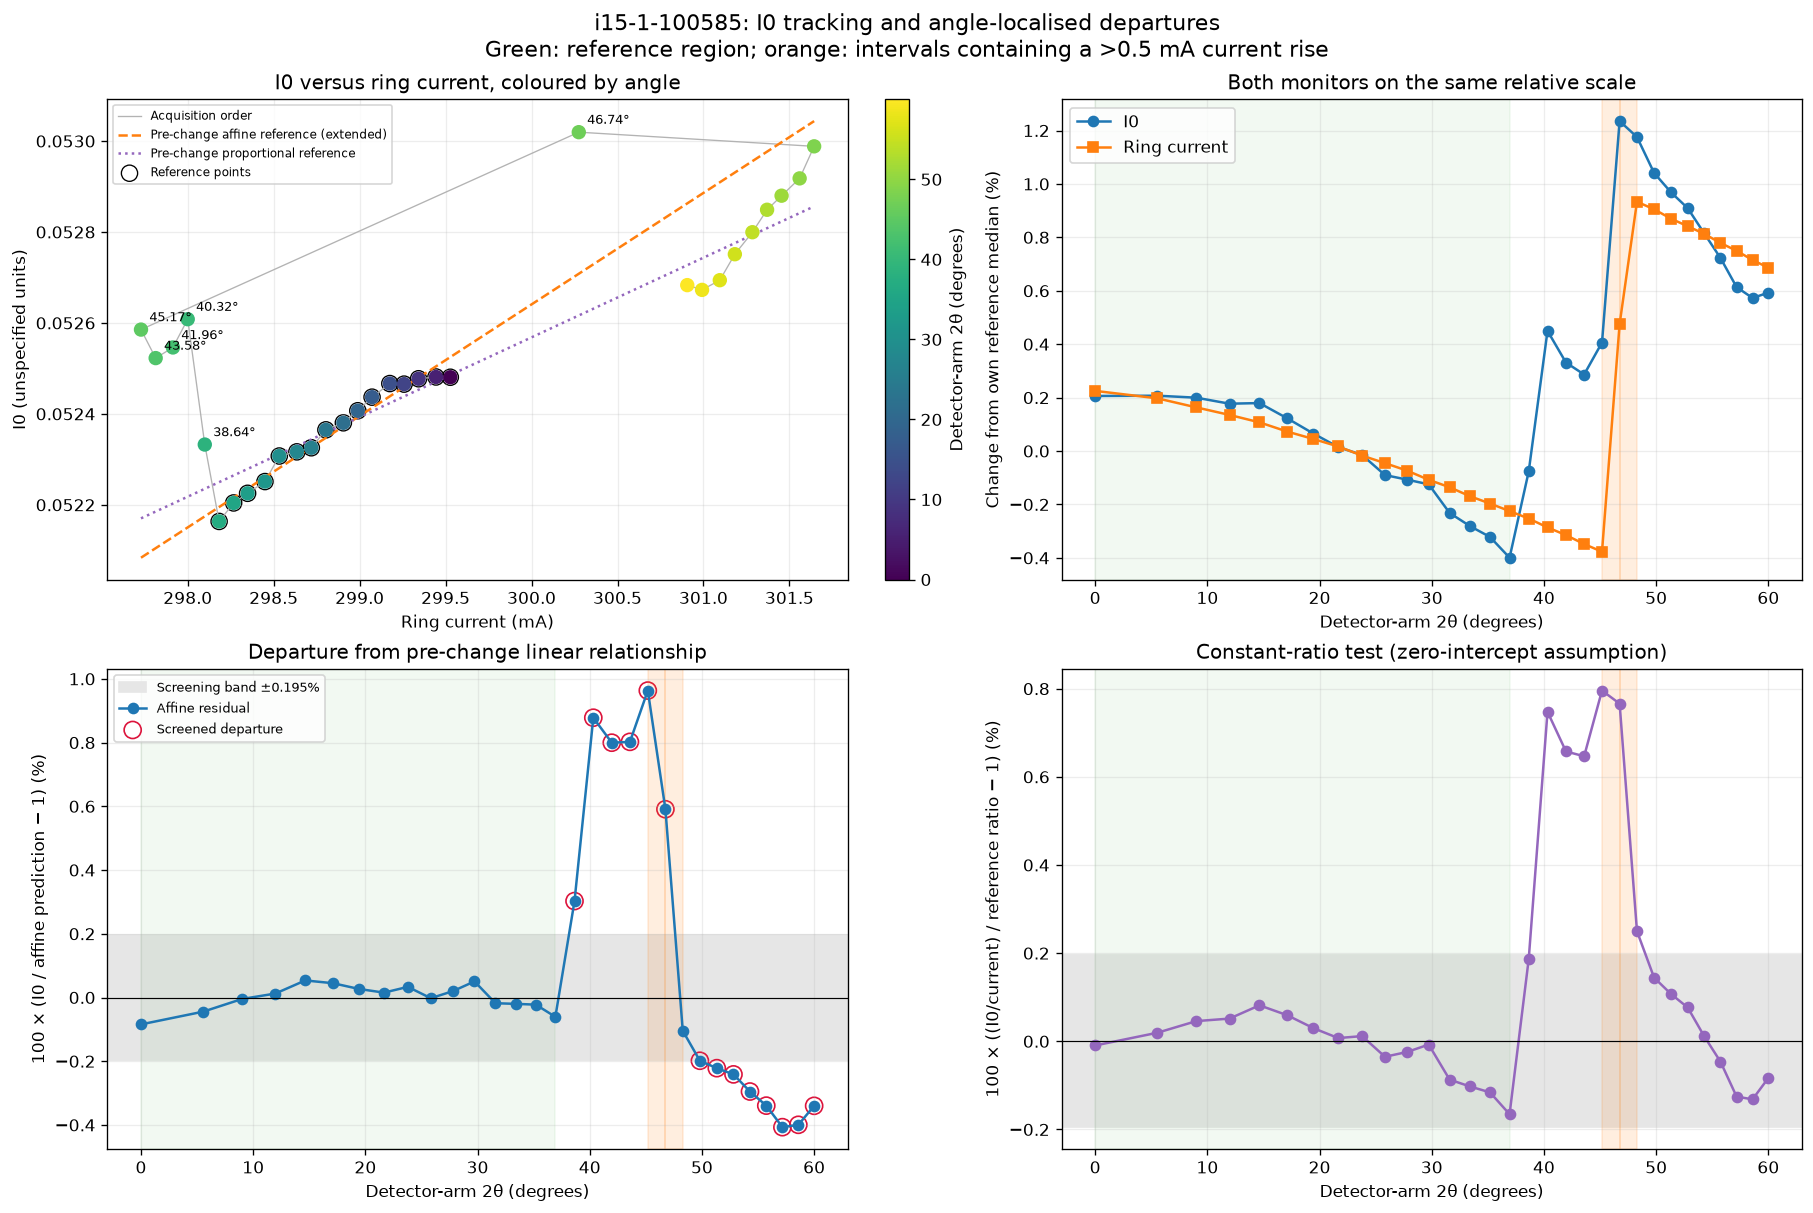

In [5]:
plt.rcParams.update({'figure.dpi': 120, 'axes.grid': True, 'grid.alpha': 0.22})
fig, axes = plt.subplots(2, 2, figsize=(15, 10), constrained_layout=True)
valid = points.valid
p = points.loc[valid]
angles = p.two_theta_deg.to_numpy()

ax = axes[0, 0]
sc = ax.scatter(p.ring_current_mA, p.i0, c=angles, cmap='viridis', s=58, zorder=3)
ax.plot(p.ring_current_mA, p.i0, color='0.7', lw=0.8, label='Acquisition order')
c_grid = np.linspace(p.ring_current_mA.min(), p.ring_current_mA.max(), 200)
ax.plot(c_grid, slope * (c_grid - c_ref) + intercept_at_ref, '--', color='tab:orange', label='Pre-change affine reference (extended)')
ax.plot(c_grid, ratio_reference * c_grid, ':', color='tab:purple', label='Pre-change proportional reference')
ax.scatter(points.loc[reference, 'ring_current_mA'], points.loc[reference, 'i0'], facecolors='none', edgecolors='black', s=95, lw=0.8, label='Reference points')
for row in p.loc[p.flag_affine & (p.affine_residual_percent > 0)].itertuples():
    ax.annotate(f'{row.two_theta_deg:.2f}°', (row.ring_current_mA, row.i0), xytext=(5, 5), textcoords='offset points', fontsize=8)
fig.colorbar(sc, ax=ax, label='Detector-arm 2θ (degrees)')
ax.set(xlabel='Ring current (mA)', ylabel=f'I0 ({i0_units})', title='I0 versus ring current, coloured by angle')
ax.ticklabel_format(axis='y', style='plain', useOffset=False)
ax.legend(fontsize=7)

ax = axes[0, 1]
ax.plot(angles, 100 * (p.i0 / points.loc[reference, 'i0'].median() - 1), 'o-', label='I0')
ax.plot(angles, 100 * (p.ring_current_mA / points.loc[reference, 'ring_current_mA'].median() - 1), 's-', label='Ring current')
ax.set(xlabel='Detector-arm 2θ (degrees)', ylabel='Change from own reference median (%)', title='Both monitors on the same relative scale')
ax.legend()

ax = axes[1, 0]
ax.axhspan(-threshold_percent, threshold_percent, color='0.9', label=f'Screening band ±{threshold_percent:.3f}%')
ax.plot(angles, p.affine_residual_percent, 'o-', color='tab:blue', label='Affine residual')
flagged = p.flag_affine
ax.scatter(p.loc[flagged, 'two_theta_deg'], p.loc[flagged, 'affine_residual_percent'], facecolors='none', edgecolors='crimson', s=105, label='Screened departure')
ax.set(xlabel='Detector-arm 2θ (degrees)', ylabel='100 × (I0 / affine prediction − 1) (%)', title='Departure from pre-change linear relationship')
ax.legend(fontsize=8)

ax = axes[1, 1]
ax.axhspan(-threshold_percent, threshold_percent, color='0.9')
ax.plot(angles, p.ratio_deviation_percent, 'o-', color='tab:purple')
ax.set(xlabel='Detector-arm 2θ (degrees)', ylabel='100 × ((I0/current) / reference ratio − 1) (%)', title='Constant-ratio test (zero-intercept assumption)')

jump_rows = points.loc[points.current_jump]
for ax in (axes[0, 1], axes[1, 0], axes[1, 1]):
    ax.axvspan(points.loc[reference, 'two_theta_deg'].min(), points.loc[reference, 'two_theta_deg'].max(), color='tab:green', alpha=0.06)
    for row in jump_rows.itertuples():
        previous_angle = points.loc[row.Index - 1, 'two_theta_deg']
        ax.axvspan(previous_angle, row.two_theta_deg, color='tab:orange', alpha=0.13)
    if ax in (axes[1, 0], axes[1, 1]):
        ax.axhline(0, color='black', lw=0.7)
fig.suptitle('i15-1-100585: I0 tracking and angle-localised departures\nGreen: reference region; orange: intervals containing a >0.5 mA current rise', fontsize=13)
plt.show()

In [6]:
# Contiguous flagged runs are scan-point ranges, not precisely known change boundaries.
def flagged_runs(flag_column):
    mask = points[flag_column].to_numpy(dtype=bool)
    indices = np.flatnonzero(mask)
    if not len(indices):
        return pd.DataFrame()
    groups = np.split(indices, np.flatnonzero(np.diff(indices) > 1) + 1)
    rows = []
    residual_column = 'affine_residual_percent' if flag_column == 'flag_affine' else 'ratio_deviation_percent'
    for group in groups:
        subset = points.iloc[group]
        rows.append({'test': flag_column, 'first_point_0based': int(subset.point.iloc[0]), 'last_point_0based': int(subset.point.iloc[-1]), 'first_angle_deg': subset.two_theta_deg.iloc[0], 'last_angle_deg': subset.two_theta_deg.iloc[-1], 'points': len(subset), 'min_residual_percent': subset[residual_column].min(), 'max_residual_percent': subset[residual_column].max()})
    return pd.DataFrame(rows)

display(Markdown('### Flagged point ranges (model-dependent screening)'))
display(pd.concat([flagged_runs('flag_affine'), flagged_runs('flag_proportional')], ignore_index=True).round(4))
display(Markdown('### Current-rise intervals'))
jump_table = points.loc[points.current_jump, ['point', 'two_theta_deg', 'ring_current_mA', 'current_step_mA']].copy()
jump_table.insert(1, 'previous_angle_deg', points.two_theta_deg.shift(1).loc[jump_table.index])
display(jump_table.round(6))
display(Markdown('### Detailed suspect region / transition (all departures retained in `points`)'))
display(points.loc[points.two_theta_deg.between(37, 50), result_columns].round(6))

# Basic checks of pairing and reference calculations.
assert points.point.is_unique and len(points) == 31
assert np.isfinite(points.loc[points.valid, ['affine_residual_percent', 'ratio_deviation_percent']].to_numpy()).all()
assert np.allclose(points.i0_per_mA * points.ring_current_mA, points.i0)
assert abs(np.mean(ref_residual * points.loc[reference, 'affine_expected_i0'])) < 1e-10
print('Pairing, finite predictions, ratio reconstruction and reference-fit checks passed.')

### Flagged point ranges (model-dependent screening)

,test,first_point_0based,last_point_0based,first_angle_deg,last_angle_deg,points,min_residual_percent,max_residual_percent
0,flag_affine,16,21,38.6412,46.7434,6,0.3026,0.9633
1,flag_affine,23,30,49.8168,60.0000,8,-0.4069,-0.1986
2,flag_proportional,17,22,40.3163,48.2906,6,0.2498,0.7958


### Current-rise intervals

,point,previous_angle_deg,two_theta_deg,ring_current_mA,current_step_mA
21,21,45.173895,46.743384,300.274785,2.546634
22,22,46.743384,48.290620,301.643855,1.369070


### Detailed suspect region / transition (all departures retained in `points`)

,point,two_theta_deg,ring_current_mA,i0,affine_residual_percent,ratio_deviation_percent,extrapolated,flag_affine,flag_proportional,current_jump
16,16,38.641175,298.099203,0.052333,0.302625,0.186292,True,True,False,False
17,17,40.316321,297.999975,0.052608,0.878066,0.747609,True,True,True,False
18,18,41.962112,297.913845,0.052546,0.799699,0.657665,True,True,True,False
19,19,43.580711,297.813517,0.052523,0.802367,0.646716,True,True,True,False
20,20,45.173895,297.728151,0.052585,0.963281,0.795773,True,True,True,False
21,21,46.743384,300.274785,0.053020,0.590794,0.766096,True,True,True,True
22,22,48.290620,301.643855,0.052988,-0.104575,0.249834,True,False,True,True
23,23,49.816825,301.559493,0.052918,-0.198550,0.144472,True,True,False,False


Pairing, finite predictions, ratio reconstruction and reference-fit checks passed.


## Findings for this scan

- **Onset lies between the sampled positions 36.9343° and 38.6412°.** At 38.6412° I0 rises even though ring current continues to fall. The affine-reference excess is **+0.303%**. The first point does not exceed the same threshold under the proportional model, so the exact flagged onset depends on the reference assumption.
- **The clearest pre-current-jump mismatch is at 40.3163°, 41.9621°, 43.5807° and 45.1739°.** Affine excesses are **+0.878%, +0.800%, +0.802% and +0.963%**, respectively; the proportional model also flags all four. This is not explained by the later recorded ring-current increase alone.
- **Treat 46.7434° and 48.2906° as a current-rise transition.** Current increases by **2.5466 mA**, then **1.3691 mA**, consistent with top-up. At 46.7434° the excess remains +0.591% affine / +0.766% proportional. At 48.2906° the tests disagree (−0.105% / +0.250%). Different monitor sampling/averaging windows could matter here, but are not proven to be the cause.
- **49.8168°–60° is model-dependent, not a confirmed continuation of the positive offset.** The affine model flags −0.199% to −0.407%, whereas the proportional deviations remain within ±0.145%. These currents are outside the pre-change fitted range, so do not reject this region solely on the extrapolated affine fit.

**Practical review region:** inspect detector positions **38.64°–48.29°**, with the strongest agreement between both screening models at **40.32°–46.74°**. These bounds describe sampled positions; the true change times/angles are not resolved between points. They do not identify individual diffraction bins affected within an image.

**Interpretation limits:** this scan establishes a change in I0/ring-current tracking, not which signal is wrong. Beamline transmission/beam-position changes, I0 electronics, or asynchronous monitor readings remain hypotheses. Angle and acquisition order are confounded in this single monotonic scan; a repeat or timestamped beamline logs would distinguish an angular dependence from a time-dependent event. No automatic masking or correction is applied. The numerical findings above correspond to the default reference and threshold settings; rerun the analysis and consult the generated tables if those are changed.

In [7]:
# Audit timing metadata before aligning pitch changes with scan points.
timing_metadata = []
with h5py.File(NEXUS_PATH, 'r') as nexus:
    def inspect_timing(name, obj):
        if isinstance(obj, h5py.Dataset) and any(word in name.lower() for word in ('time', 'epoch', 'duration')):
            record = {'path': name, 'shape': obj.shape, 'dtype': str(obj.dtype), 'units': str(obj.attrs.get('units', ''))}
            if obj.size <= 100 and not obj.dtype.hasobject:
                record['values'] = str(obj[()])
            elif obj.size <= 2:
                record['values'] = str(obj[()])
            timing_metadata.append(record)
    nexus.visititems(inspect_timing)
display(pd.DataFrame(timing_metadata))

,path,shape,dtype,units,values
0,entry/diamond_scan/duration,(),int64,b'ms',425071
1,entry/diamond_scan/end_time,(),|S1024,,b'2026-10-15T21:42:28.820'
2,entry/diamond_scan/scan_dead_time,(),int64,b'ms',0
3,entry/diamond_scan/scan_dead_time_percent,(),float32,,nan
4,entry/diamond_scan/scan_estimated_duration,(),int64,b'ms',0
5,entry/diamond_scan/start_time,(),object,,b'2026-10-15T21:35:23.749'
6,entry/instrument/i0/driver-averaging_time,(),float64,b'',10.0
7,entry/instrument/i0/driver-sample_time,(),float64,b'',0.001
8,entry/plan_metadata/exposure_time_per_frame,(),float64,,10.0


## Monochromator pitch readback: change-only archive

Use **BL15J-OP-LAUE-01:PITCH.RBV only**, not the setpoint. Hold each valid readback until its next change (a right-continuous step signal); do not interpolate pitch. Ignore missing RBV values and collapse repeated readbacks introduced by changes in the other channel. Keep the last valid value before the scan as the initial state.

**Explicit timezone assumptions:** naive NeXus times are UTC (container clock); naive CSS export times are Europe/London local time (BST on 15 October). Thus the scan spans **22:35:23.749–22:42:28.820 BST**. Neither source string states its timezone, so this alignment remains conditional on those assumptions.

The timing audit above found no per-point timestamps. For visual comparison only, distribute the 31 points over equal slots within the recorded scan interval, using slot centres. These are **estimated times, not measured timestamps or exposure boundaries**. Motor motion and acquisition overhead can shift the angle-to-time mapping. Event times from the archive remain exact as exported; angle associations are approximate. Pitch units are not specified in the export.

In [9]:
PITCH_EXPORT_PATH = Path('/dls/i15-1/data/2026/cm44163-4/processing/dean/100585-pitch-angle.txt')
NEXUS_TIMEZONE = 'UTC'
ARCHIVE_TIMEZONE = 'Europe/London'

# Read only the first channel's value, severity and status; never use the setpoint.
export_lines = PITCH_EXPORT_PATH.read_text().splitlines()
header = next(line for line in export_lines if line.startswith('# Time'))
assert 'PITCH.RBV Value' in header.split('\t')[1], 'First data column is not pitch RBV.'
archive_rows = []
for line in export_lines:
    if not line.strip() or line.startswith('#'):
        continue
    fields = line.split('\t')
    if len(fields) < 4:
        raise ValueError(f'Malformed archive row: {line}')
    archive_rows.append({'time_text': fields[0], 'pitch_rbv': pd.to_numeric(fields[1], errors='coerce'), 'severity': fields[2], 'status': fields[3]})
pitch_raw = pd.DataFrame(archive_rows)
pitch_raw['time_bst'] = pd.to_datetime(pitch_raw.time_text).dt.tz_localize(ARCHIVE_TIMEZONE).dt.tz_convert('Europe/London')
pitch_raw = pitch_raw.sort_values('time_bst', kind='stable')
assert not pitch_raw.time_bst.duplicated().any(), 'Duplicate archive timestamps need review.'
missing_rbv_rows = int(pitch_raw.pitch_rbv.isna().sum())
pitch_valid = pitch_raw.loc[pitch_raw.pitch_rbv.notna()].copy()
if not ((pitch_valid.severity == 'NONE') & (pitch_valid.status == 'NO_ALARM')).all():
    raise ValueError('Pitch readback has alarm records; review before carrying forward.')
pitch_events = pitch_valid.loc[pitch_valid.pitch_rbv.ne(pitch_valid.pitch_rbv.shift())].copy()
pitch_events['delta_rbv'] = pitch_events.pitch_rbv.diff()

def nexus_local_time(value):
    stamp = pd.Timestamp(value)
    if stamp.tzinfo is None:
        stamp = stamp.tz_localize(NEXUS_TIMEZONE)
    return stamp.tz_convert('Europe/London')

scan_start_bst = nexus_local_time(start_time)
scan_end_bst = nexus_local_time(end_time)
scan_duration_seconds = (scan_end_bst - scan_start_bst).total_seconds()
assert scan_duration_seconds > 0
# Bound carry-forward by the export's declared coverage, not by its last event.
archive_start = pd.Timestamp(next(line.split(' : ', 1)[1] for line in export_lines if line.startswith('# Start Time'))).tz_localize(ARCHIVE_TIMEZONE).tz_convert('Europe/London')
archive_end = pd.Timestamp(next(line.split(': ', 1)[1] for line in export_lines if line.startswith('# End Time'))).tz_localize(ARCHIVE_TIMEZONE).tz_convert('Europe/London')
assert archive_start <= scan_start_bst < scan_end_bst <= archive_end
initial_pitch = pitch_events.loc[pitch_events.time_bst <= scan_start_bst].tail(1)
assert len(initial_pitch) == 1, 'No valid RBV state at scan start.'
in_scan_pitch_events = pitch_events.loc[pitch_events.time_bst.between(scan_start_bst, scan_end_bst)].copy()

point_timing = points.copy()
point_timing['estimated_time_bst'] = pd.DatetimeIndex([
    scan_start_bst + pd.Timedelta(seconds=(index + 0.5) * scan_duration_seconds / len(points))
    for index in range(len(points))
])
point_timing = pd.merge_asof(
    point_timing.sort_values('estimated_time_bst'),
    pitch_events[['time_bst', 'pitch_rbv']].rename(columns={'time_bst': 'last_rbv_change_bst'}),
    left_on='estimated_time_bst', right_on='last_rbv_change_bst', direction='backward'
)
assert point_timing.pitch_rbv.notna().all()
# Approximate angle at each archive event under the equal-slot timing model.
# Do not clamp an event beyond the last point centre to the last angle.
event_seconds = (in_scan_pitch_events.time_bst - scan_start_bst).dt.total_seconds()
estimated_point_seconds = (point_timing.estimated_time_bst - scan_start_bst).dt.total_seconds()
in_scan_pitch_events['estimated_angle_deg'] = np.interp(event_seconds, estimated_point_seconds, point_timing.two_theta_deg, left=np.nan, right=np.nan)
print(f'Conditional scan interval: {scan_start_bst} to {scan_end_bst}')
print(f'Missing RBV rows ignored: {missing_rbv_rows}; genuine RBV states retained: {len(pitch_events)}')
print(f'Initial pitch RBV: {initial_pitch.pitch_rbv.iloc[0]:.6f} (export units unspecified)')
display(in_scan_pitch_events[['time_bst', 'pitch_rbv', 'delta_rbv', 'estimated_angle_deg']])
display(point_timing.loc[point_timing.two_theta_deg.between(35, 50), ['point', 'two_theta_deg', 'estimated_time_bst', 'pitch_rbv', 'affine_residual_percent', 'ratio_deviation_percent']].round({'two_theta_deg': 6, 'pitch_rbv': 6, 'affine_residual_percent': 6, 'ratio_deviation_percent': 6}))
# Prove carry-forward (no future observations used) and removal of repeated states.
assert (point_timing.last_rbv_change_bst <= point_timing.estimated_time_bst).all()
assert pitch_events.pitch_rbv.diff().iloc[1:].ne(0).all()
assert point_timing.estimated_time_bst.between(scan_start_bst, scan_end_bst).all()

Conditional scan interval: 2026-10-15 22:35:23.749000+01:00 to 2026-10-15 22:42:28.820000+01:00
Missing RBV rows ignored: 1; genuine RBV states retained: 8
Initial pitch RBV: -8.863009 (export units unspecified)


,time_bst,pitch_rbv,delta_rbv,estimated_angle_deg
9,2026-10-15 22:39:10.487907398+01:00,-8.862014,0.000995,38.701213
11,2026-10-15 22:42:23.303258412+01:00,-8.861019,0.000995,NaN


,point,two_theta_deg,estimated_time_bst,pitch_rbv,affine_residual_percent,ratio_deviation_percent
14,14,35.192995,2026-10-15 22:38:42.572532258+01:00,-8.863009,-0.022412,-0.115826
15,15,36.934288,2026-10-15 22:38:56.284500+01:00,-8.863009,-0.060685,-0.165391
16,16,38.641175,2026-10-15 22:39:09.996467741+01:00,-8.863009,0.302625,0.186292
17,17,40.316321,2026-10-15 22:39:23.708435483+01:00,-8.862014,0.878066,0.747609
18,18,41.962112,2026-10-15 22:39:37.420403225+01:00,-8.862014,0.799699,0.657665
19,19,43.580711,2026-10-15 22:39:51.132370967+01:00,-8.862014,0.802367,0.646716
20,20,45.173895,2026-10-15 22:40:04.844338709+01:00,-8.862014,0.963281,0.795773
21,21,46.743384,2026-10-15 22:40:18.556306451+01:00,-8.862014,0.590794,0.766096
22,22,48.290620,2026-10-15 22:40:32.268274193+01:00,-8.862014,-0.104575,0.249834
23,23,49.816825,2026-10-15 22:40:45.980241935+01:00,-8.862014,-0.198550,0.144472


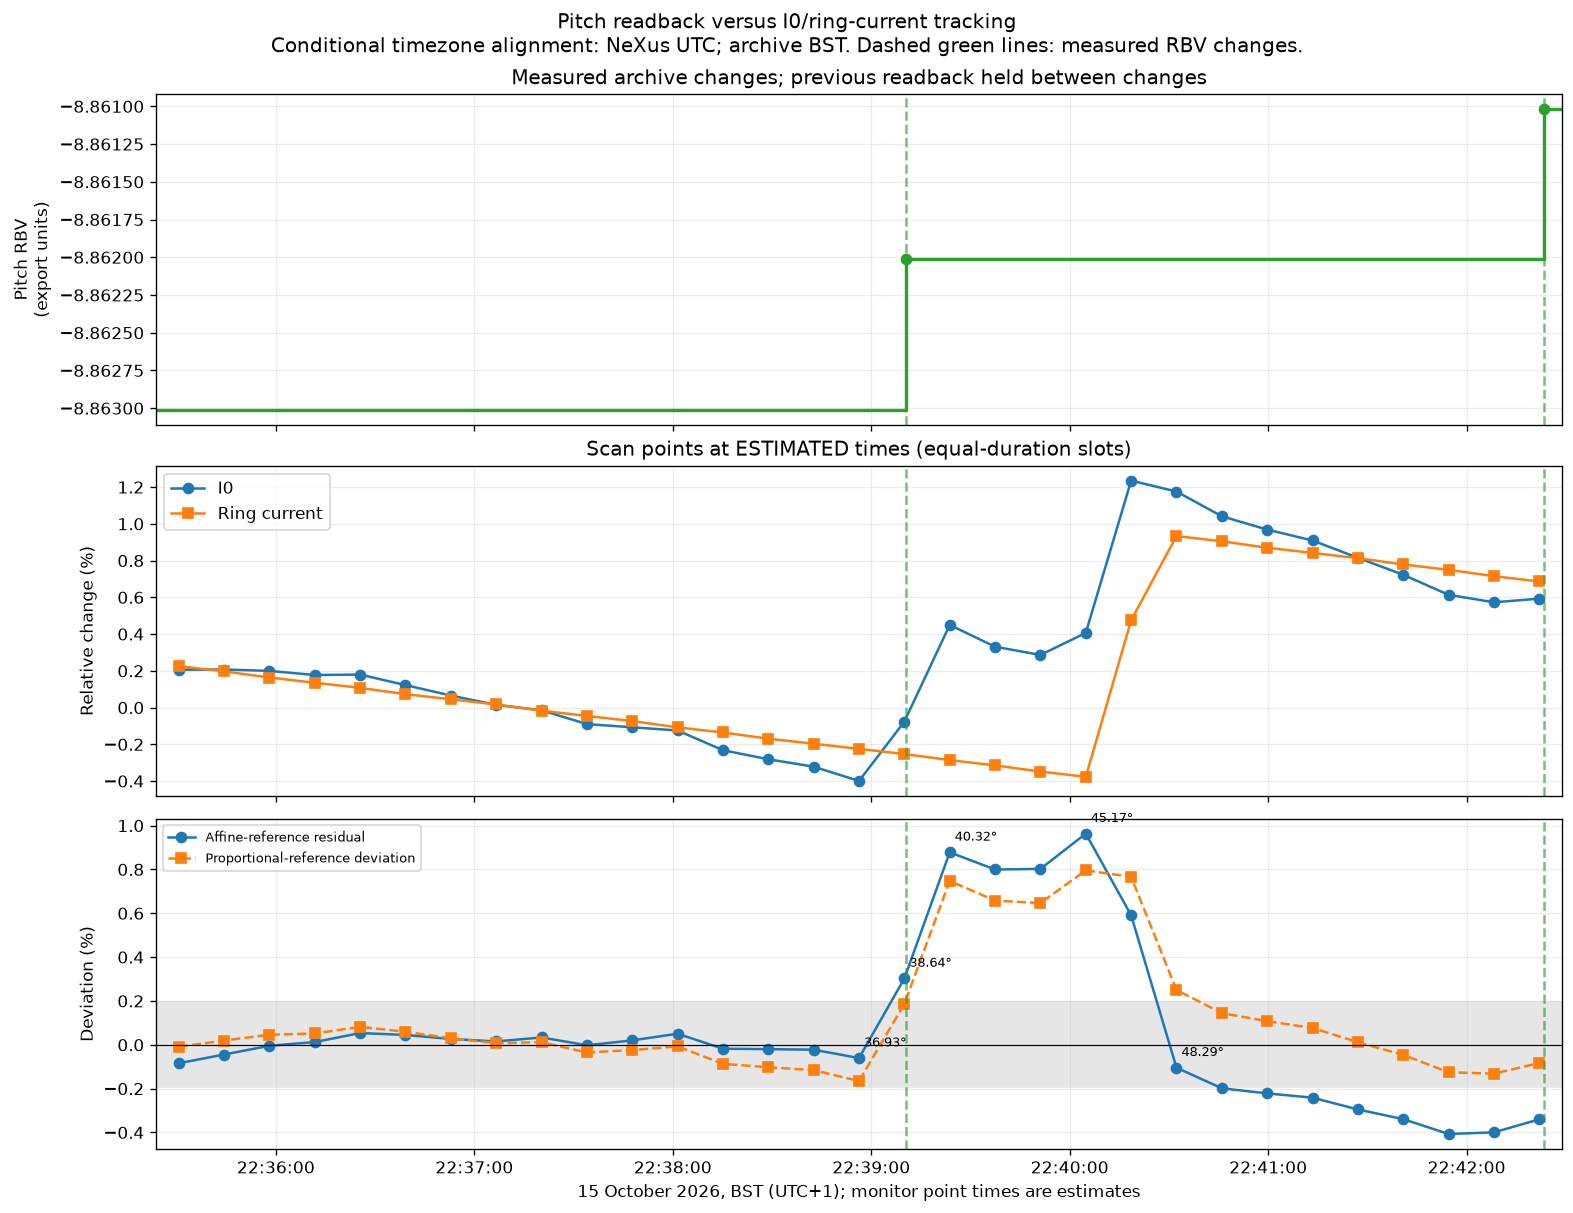

In [10]:
import matplotlib.dates as mdates
from zoneinfo import ZoneInfo

# Start with the carried-forward initial state and extend the final state to scan end.
pitch_plot_times = [scan_start_bst, *in_scan_pitch_events.time_bst.tolist(), scan_end_bst]
pitch_plot_values = [initial_pitch.pitch_rbv.iloc[0], *in_scan_pitch_events.pitch_rbv.tolist()]
pitch_plot_values.append(pitch_plot_values[-1])
fig_pitch, pitch_axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True, constrained_layout=True)
ax = pitch_axes[0]
ax.step(pitch_plot_times, pitch_plot_values, where='post', color='tab:green', lw=2)
ax.scatter(in_scan_pitch_events.time_bst, in_scan_pitch_events.pitch_rbv, color='tab:green', zorder=3)
ax.set(ylabel='Pitch RBV\n(export units)', title='Measured archive changes; previous readback held between changes')
ax.ticklabel_format(axis='y', style='plain', useOffset=False)

ax = pitch_axes[1]
ax.plot(point_timing.estimated_time_bst, 100 * (point_timing.i0 / points.loc[reference, 'i0'].median() - 1), 'o-', label='I0')
ax.plot(point_timing.estimated_time_bst, 100 * (point_timing.ring_current_mA / points.loc[reference, 'ring_current_mA'].median() - 1), 's-', label='Ring current')
ax.set(ylabel='Relative change (%)', title='Scan points at ESTIMATED times (equal-duration slots)')
ax.legend()

ax = pitch_axes[2]
ax.axhspan(-threshold_percent, threshold_percent, color='0.9')
ax.plot(point_timing.estimated_time_bst, point_timing.affine_residual_percent, 'o-', label='Affine-reference residual')
ax.plot(point_timing.estimated_time_bst, point_timing.ratio_deviation_percent, 's--', label='Proportional-reference deviation')
for index in (15, 16, 17, 20, 22):
    row = point_timing.iloc[index]
    ax.annotate(f'{row.two_theta_deg:.2f}°', (row.estimated_time_bst, row.affine_residual_percent), xytext=(3, 7), textcoords='offset points', fontsize=8)
ax.axhline(0, color='black', lw=0.7)
ax.set(ylabel='Deviation (%)', xlabel='15 October 2026, BST (UTC+1); monitor point times are estimates')
ax.legend(fontsize=8)
for ax in pitch_axes:
    for event_time in in_scan_pitch_events.time_bst:
        ax.axvline(event_time, color='tab:green', ls='--', alpha=0.65)
    ax.set_xlim(scan_start_bst, scan_end_bst)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M:%S', tz=ZoneInfo('Europe/London')))
fig_pitch.suptitle('Pitch readback versus I0/ring-current tracking\nConditional timezone alignment: NeXus UTC; archive BST. Dashed green lines: measured RBV changes.', fontsize=12)
plt.show()

### Pitch comparison: interpretation

Under the stated UTC/BST alignment:

- The scan starts with pitch RBV **−8.863009**. At **22:39:10.487907398 BST** it changes to **−8.862014**, a step of **+0.000995 in the export's unspecified units**.
- That step is very close to the observed I0 anomaly onset. The equal-slot timing model places the **38.6412°** point at **22:39:09.996 BST** and the **40.3163°** point at **22:39:23.708 BST**. The first is only about **0.49 s before the archived RBV change**, but the point time is an estimate, so this is not evidence that I0 led pitch. A change during an averaging/exposure window could also give a partially changed first reading, but actual windows are unavailable.
- The equal-slot model maps the first pitch event to roughly **38.7°**. This apparent precision comes from interpolation, not measured point timestamps: report it as **near the 38.64° onset**, not an exact affected angle.
- RBV remains at **−8.862014** throughout the main positive I0 offset and its subsequent reduction around the ring-current rise. Therefore pitch is a **plausible contributor to the onset**, but this record does **not explain the entire residual evolution as a simple function of pitch alone**. Constant archived RBV does not exclude motion below archive resolution/deadband or other beamline changes.
- A second equal RBV step, to **−8.861019**, occurs at **22:42:23.303258412 BST**, just **5.52 s before the recorded scan end**. It is after the last estimated point centre; without measured exposure times it cannot be assigned reliably to the final detector frame. The apparent final I0 uptick is not sufficient evidence for another pitch response.

**Conclusion:** the pitch step and I0 onset are temporally consistent within the available timing limitations, making monochromator pitch a credible candidate. This is association, not proof of causation or a calibration of intensity versus pitch. Confirm with actual per-point timestamps/scan logs and, ideally, time-resolved I0 and ring-current archive records. No setpoint data were used and no beamline files were modified.